<a href="https://www.kaggle.com/code/maryammoghaddasbayat/aipolicy-2november?scriptVersionId=364910446" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Stakeholder Power Dynamics and Governance Asymmetries in AI Policy

**Team MK** – Maryam Moghaddas Bayat & Kelvin Obour Coleman

**Dataset:** AIPolicyTracker Open Data (policies, obligations, jurisdictions, implementation).

**Analysis pipeline:** data loading → merging → two independent rule-based coding procedures → inter-method agreement → RQ1 stakeholder recognition and protection → RQ2 binding and voluntary accountability → RQ3 regression → RQ4 actor references and implementation records.

**Important scope note:** The automated text coding identifies textual indicators. It does not independently establish legal enforceability or verify that an actor has a legally assigned duty. Legal interpretation requires examination of the relevant source provision.

## 0. Packages, settings and output folders

This notebook saves tables as CSV files and figures as PDF files in the Kaggle working directory. It does not rerun any machine-learning training.

In [1]:
import os
import re
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from sklearn.metrics import cohen_kappa_score
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 100)

SEED = 42
rng = np.random.default_rng(SEED)

try:
    from IPython.display import display, Markdown
except ImportError:
    display = print
    Markdown = str

OUT = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
os.makedirs(OUT, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.bbox": "tight",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10
})

SAVED = {"tables": [], "figures": []}

def show(obj, title, fname=None, index=True):
    """Display an object and save DataFrames/Series as CSV."""
    display(Markdown(f"**{title}**"))
    display(obj)
    if fname is not None:
        if isinstance(obj, pd.Series):
            obj = obj.to_frame()
        obj.to_csv(os.path.join(OUT, f"{fname}.csv"), index=index)
        SAVED["tables"].append(f"{fname}.csv")

def savefig(name):
    """Save the current figure as a vector PDF and display it."""
    fig = plt.gcf()
    fig.savefig(os.path.join(OUT, f"{name}.pdf"), format="pdf")
    SAVED["figures"].append(f"{name}.pdf")
    plt.show()
    plt.close(fig)

## 1. Load the four dataset files

Attach the AIPolicyTracker dataset to the Kaggle notebook before running this section. The file search looks for the four CSV files under `/kaggle/input`.

In [2]:
DATA_FOLDER = "AIpolicy_29OK"
ROOTS = ["/kaggle/input", "."]

def find_csv(name):
    hits = []
    for root in ROOTS:
        if not os.path.exists(root):
            continue
        for dirpath, _, files in os.walk(root):
            for filename in files:
                if filename.lower().endswith(".csv") and name.lower() in filename.lower():
                    hits.append(os.path.join(dirpath, filename))

    if not hits:
        raise FileNotFoundError(
            f"Could not find a CSV containing '{name}'. Check the attached Kaggle dataset."
        )

    folder_key = re.sub(r"[^a-z0-9]", "", DATA_FOLDER.lower())
    hits.sort(key=lambda p: (
        0 if folder_key in re.sub(r"[^a-z0-9]", "", p.lower()) else 1,
        len(p)
    ))
    print(f"{name:16s} -> {hits[0]}")
    return hits[0]

pol = pd.read_csv(find_csv("policies"))
obl = pd.read_csv(find_csv("obligations"))
jur = pd.read_csv(find_csv("jurisdictions"))
imp = pd.read_csv(find_csv("implementation"))

sizes = pd.DataFrame(
    {name: frame.shape for name, frame in [
        ("policies", pol), ("obligations", obl),
        ("jurisdictions", jur), ("implementation", imp)
    ]},
    index=["rows", "columns"]
).T

show(sizes, "Table 1. Dataset sizes", "t01_dataset_sizes")

policies         -> /kaggle/input/datasets/maryammoghaddasbayat/aipolicy-29ok/aipolicytracker-policies.csv
obligations      -> /kaggle/input/datasets/maryammoghaddasbayat/aipolicy-29ok/aipolicytracker-obligations.csv
jurisdictions    -> /kaggle/input/datasets/maryammoghaddasbayat/aipolicy-29ok/aipolicytracker-jurisdictions.csv
implementation   -> /kaggle/input/datasets/maryammoghaddasbayat/aipolicy-29ok/aipolicytracker-implementation.csv


**Table 1. Dataset sizes**

,rows,columns
policies,244,25
obligations,117,18
jurisdictions,249,20
implementation,8,27


## 2. Clean, merge and construct analysis variables

The policy document is the unit for stakeholder coding and regression. The obligation is the unit for RQ4 actor-reference counts. The implementation file contains only eight records and is therefore summarised descriptively.

Policies with jurisdiction match: 1.0


**Table 2. Corpus composition**

,variable,category,n_policies,share
0,law_type,non-binding (soft law),163,0.668
1,law_type,binding (hard law),81,0.332
2,format,strategy,99,0.406
3,format,statute,76,0.311
4,format,soft_guidance,35,0.143
5,format,policy,30,0.123
6,format,consultation,4,0.016
7,tier,country,164,0.672
8,tier,state,67,0.275
9,tier,supranational,13,0.053


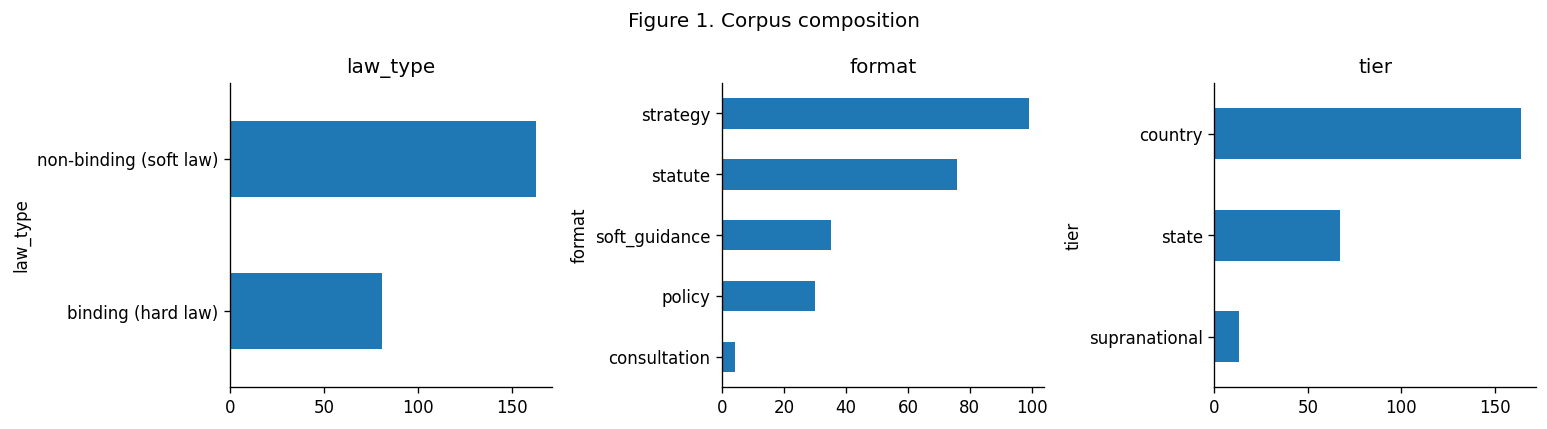

Policy records: 244
Obligation records: 117
Jurisdiction records: 249
Implementation records: 8


In [3]:
# Convert available date columns to datetime.
for col in ["adopted_on", "published_on", "in_force_on", "applies_from"]:
    if col in pol.columns:
        pol[col] = pd.to_datetime(pol[col], errors="coerce")

if "applies_from" in obl.columns:
    obl["applies_from"] = pd.to_datetime(obl["applies_from"], errors="coerce")

# Join jurisdiction metadata to policies.
required_jur_cols = ["slug", "jurisdiction_type", "region", "subregion"]
missing_jur_cols = [c for c in required_jur_cols if c not in jur.columns]
if missing_jur_cols:
    raise KeyError(f"Missing jurisdiction columns: {missing_jur_cols}")

jt = jur[required_jur_cols].rename(columns={"slug": "jurisdiction"})
pol = pol.merge(jt, on="jurisdiction", how="left", validate="many_to_one")
print("Policies with jurisdiction match:",
      round(pol["jurisdiction_type"].notna().mean(), 3))

FORMAT_MAP = {
    "act": "statute",
    "regulation": "statute",
    "bill": "statute",
    "executive_order": "statute",
    "strategy": "strategy",
    "policy": "policy",
    "guidance": "soft_guidance",
    "framework": "soft_guidance",
    "standard": "soft_guidance",
    "code_of_practice": "soft_guidance",
    "consultation": "consultation"
}
pol["format"] = pol["instrument_type"].map(FORMAT_MAP).fillna("other")

# Collapse sparse format categories for the regression controls.
pol["format3"] = pol["format"].replace({
    "strategy": "strategy_policy",
    "policy": "strategy_policy",
    "consultation": "strategy_policy"
})

# Collapse territory/region to state level for descriptive control categories.
pol["tier"] = pol["jurisdiction_type"].replace({
    "territory": "state",
    "region": "state"
})

pol["law_type"] = np.where(
    pol["is_binding"].fillna(False).astype(bool),
    "binding (hard law)",
    "non-binding (soft law)"
)

# Build obligation text and aggregate linked obligations to the policy level.
for col in ["title", "summary", "practical_action"]:
    if col not in obl.columns:
        obl[col] = ""

obl["obl_text"] = (
    obl["title"].fillna("").astype(str) + ". " +
    obl["summary"].fillna("").astype(str) + ". " +
    obl["practical_action"].fillna("").astype(str)
)

obl_agg = (
    obl.groupby("policy", dropna=False)
       .agg(
           n_obligations=("slug", "count"),
           obl_text=("obl_text", lambda x: " ".join(x.dropna().astype(str)))
       )
       .reset_index()
       .rename(columns={"policy": "slug"})
)

pol = pol.merge(obl_agg, on="slug", how="left", validate="one_to_one")
pol["n_obligations"] = pol["n_obligations"].fillna(0).astype(int)

for col in ["title", "summary_plain", "who_it_applies_to"]:
    if col not in pol.columns:
        pol[col] = ""

pol["text"] = (
    pol["title"].fillna("").astype(str) + ". " +
    pol["summary_plain"].fillna("").astype(str) + ". " +
    pol["who_it_applies_to"].fillna("").astype(str) + ". " +
    pol["obl_text"].fillna("").astype(str)
)

desc_parts = []
for col in ["law_type", "format", "tier"]:
    tmp = pol[col].value_counts(dropna=False).rename("n_policies").to_frame()
    tmp["variable"] = col
    tmp["category"] = tmp.index.astype(str)
    desc_parts.append(tmp.reset_index(drop=True))
desc = pd.concat(desc_parts, ignore_index=True)
desc["share"] = (desc["n_policies"] / len(pol)).round(3)

show(desc[["variable", "category", "n_policies", "share"]],
     "Table 2. Corpus composition", "t02_corpus_composition", index=False)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ["law_type", "format", "tier"]):
    pol[col].fillna("missing").value_counts().plot(kind="barh", ax=ax)
    ax.set_title(col)
    ax.invert_yaxis()
fig.suptitle("Figure 1. Corpus composition")
plt.tight_layout()
savefig("fig01_corpus_composition")

print("Policy records:", len(pol))
print("Obligation records:", len(obl))
print("Jurisdiction records:", len(jur))
print("Implementation records:", len(imp))

## 3. Coding framework: two independent rule-based procedures

**Unit of analysis:** policy document. The text includes the title, plain-language summary, applicability information and linked obligation text.

### Stakeholder-specific coding scale

- **0 – Not mentioned:** no stakeholder-group reference detected.
- **1 – Passive recognition:** the group is mentioned, but no group-linked procedural safeguard or explicit individual right/remedy is detected in the same sentence.
- **2 – Procedural protection:** the group is mentioned in the same sentence as a procedural safeguard, such as notice, explanation, complaint, appeal, contestation or human review.
- **3 – Explicit enforceable right/remedy indicator:** the group is mentioned in the same sentence as an explicit individual right or remedy, such as a right to compensation, redress or a legal claim.

### Separate document-level variables

The overall document-level remedy scale is coded separately from stakeholder-specific scores. Public enforcement terms (for example, fines or sanctions against an organisation) are recorded separately; they are **not automatically treated as an individual stakeholder remedy**.

Coder A and Coder B use different lexicons and decision rules. Their agreement is called **inter-method agreement**, because both procedures are automated rule-based coding methods, not human coders. The conservative combined code is the lower of the two method scores and is not treated as a validated legal ground truth.

The keyword rules are indicators for structured text analysis. They cannot, by themselves, establish the legal enforceability of a provision. Source-level legal interpretation would be required for that conclusion.

In [4]:
GROUPS = [
    "consumers_individuals",
    "workers",
    "children",
    "vulnerable_groups",
    "civil_society"
]

# Different stakeholder lexicons for the two rule-based methods.
STAKEHOLDERS_A = {
    "consumers_individuals": r"\b(consumers?|individuals?|data subjects?|natural persons?|citizens?|end[- ]users?|residents?|members of the public|people)\b",
    "workers": r"\b(workers?|employees?|job applicants?|candidates?|labou?r|staff)\b",
    "children": r"\b(children|child|minors?|youth|young people)\b",
    "vulnerable_groups": r"\b(vulnerable (persons?|people|groups?)|persons? with disabilities|people with disabilities|older persons?|elderly people|patients?|marginali[sz]ed groups?)\b",
    "civil_society": r"\b(civil society|public interest groups?|non[- ]governmental organi[sz]ations?|NGOs?|affected communities|community representatives|public consultation)\b"
}

STAKEHOLDERS_B = {
    "consumers_individuals": r"(consumer|individual|data subject|natural person|citizen|end[- ]user|resident|member of the public)",
    "workers": r"(worker|employee|job applicant|candidate|labou?r|staff)",
    "children": r"(child|minor|juvenile|young person|youth)",
    "vulnerable_groups": r"(vulnerable (person|people|group)|disabilit|older person|elderly|patient|marginali[sz]ed group)",
    "civil_society": r"(civil societ|public interest group|non[- ]governmental|\bNGO\b|affected communit|community representative|public consultation)"
}

# Procedural safeguards: these are not automatically individual remedies.
PROCEDURAL_A = (
    r"\b(appeal\w*|contest\w*|challenge\w*|complain\w*|complaint\w*|"
    r"grievance\w*|human review|human intervention|notice|notification|"
    r"explanation|right to access|right to object|right to erasure|"
    r"right to opt[- ]out|opt[- ]out|request for review|review procedure)\b"
)
PROCEDURAL_B = (
    r"(appeal|contest|challeng|complain|grievance|human review|human intervention|"
    r"notice|notif|explanation|access right|right to object|erasure right|opt-?out|"
    r"request.*review|review procedure)"
)

# Explicit individual rights/remedies. General words such as "enforcement",
# "liability", "fine" and "sanction" are intentionally excluded here.
RIGHT_REMEDY_A = (
    r"\b(right to (compensation|damages|redress|a remedy)|"
    r"right of action|private right of action|claim for compensation|"
    r"seek compensation|obtain compensation|obtain redress|"
    r"entitled to compensation|entitled to damages|"
    r"judicial remedy|legal remedy|remedy for (the )?individual)\b"
)
RIGHT_REMEDY_B = (
    r"(right to (compensation|damages|redress|a remedy)|right of action|"
    r"private right of action|claim.*compensation|seek.*compensation|"
    r"obtain.*(compensation|redress)|entitled to (compensation|damages)|"
    r"judicial remedy|legal remedy|remedy.*individual)"
)

# Public enforcement is kept separate from individual rights/remedies.
PUBLIC_ENFORCEMENT_A = (
    r"\b(fines?|financial penalties|administrative penalties|sanctions?|"
    r"administrative measures|prosecution|prosecuted)\b"
)
PUBLIC_ENFORCEMENT_B = (
    r"(fine|financial penalt|administrative penalt|sanction|administrative measure|prosecut)"
)

# Symbolic/aspirational language, used for the document-level remedy scale.
SYMBOLIC_A = (
    r"\b(principles?|encourag\w+|promot\w+|voluntar\w+|should|aspirational|"
    r"ethical|ethics|trustworthy|responsible AI|guidance|best practice)\b"
)
SYMBOLIC_B = (
    r"(principle|encourag|promot|voluntar|should|aspirational|ethic|trustworthy|"
    r"responsible AI|guidance|best practice|recommend)"
)

SOFT_MODAL = re.compile(
    r"\b(should|encouraged|recommended|voluntary|aims? to|seeks? to)\b",
    re.I
)

def split_sentences(text):
    """Split on sentence-ending punctuation; retain semicolon-linked context."""
    text = str(text)
    return [
        part.strip() for part in re.split(r"(?<=[.!?])\s+", text)
        if len(part.strip()) > 3
    ]

def document_remedy_tier(sentence, method):
    """0 none; 1 symbolic; 2 procedural; 3 explicit individual right/remedy."""
    if method == "A":
        if re.search(RIGHT_REMEDY_A, sentence, re.I):
            return 3
        if re.search(PROCEDURAL_A, sentence, re.I):
            return 2
        if re.search(SYMBOLIC_A, sentence, re.I):
            return 1
    else:
        if re.search(RIGHT_REMEDY_B, sentence, re.I):
            return 3
        if re.search(PROCEDURAL_B, sentence, re.I):
            return 2
        if re.search(SYMBOLIC_B, sentence, re.I):
            return 1
    return 0

def code_policy(text, method):
    """
    Returns:
      group_scores: group-specific 0-3 scores
      remedy_score: strongest document-level remedy indicator (0-3)
      public_enforcement: separate indicator for public sanctions/penalties
    """
    stakeholder_lexicon = STAKEHOLDERS_A if method == "A" else STAKEHOLDERS_B
    group_scores = {g: 0 for g in GROUPS}
    remedy_score = 0
    public_enforcement = 0

    for sentence in split_sentences(text):
        tier = document_remedy_tier(sentence, method)

        # Method B applies a conservative cap to aspirational wording only.
        if method == "B" and SOFT_MODAL.search(sentence) and tier < 3:
            if tier == 2:
                # A clearly stated appeal/complaint/review mechanism remains procedural.
                pass
            else:
                tier = min(tier, 1)

        remedy_score = max(remedy_score, tier)

        if method == "A":
            if re.search(PUBLIC_ENFORCEMENT_A, sentence, re.I):
                public_enforcement = 1
        else:
            if re.search(PUBLIC_ENFORCEMENT_B, sentence, re.I):
                public_enforcement = 1

        for group, pattern in stakeholder_lexicon.items():
            if re.search(pattern, sentence, re.I):
                # The group must be present in the same sentence as the safeguard/right.
                group_scores[group] = max(group_scores[group], tier)

    return group_scores, remedy_score, public_enforcement

def apply_coding_method(method):
    results = [code_policy(text, method) for text in pol["text"]]
    group_df = pd.DataFrame([r[0] for r in results]).add_prefix(f"{method}_grp_")
    group_df[f"{method}_remedy"] = [r[1] for r in results]
    group_df[f"{method}_public_enforcement"] = [r[2] for r in results]
    return group_df

coded_A = apply_coding_method("A")
coded_B = apply_coding_method("B")
pol = pd.concat(
    [pol.reset_index(drop=True), coded_A.reset_index(drop=True), coded_B.reset_index(drop=True)],
    axis=1
)

for method in ["A", "B"]:
    group_cols = [f"{method}_grp_{g}" for g in GROUPS]
    pol[f"{method}_n_groups"] = (pol[group_cols] > 0).sum(axis=1)
    pol[f"{method}_inclusion"] = (pol[f"{method}_n_groups"] > 0).astype(int)
    pol[f"{method}_enforceable_remedy"] = (pol[f"{method}_remedy"] == 3).astype(int)
    pol[f"{method}_procedural_or_enforceable"] = (pol[f"{method}_remedy"] >= 2).astype(int)

print("Rule-based coding completed for", len(pol), "policy documents.")

Rule-based coding completed for 244 policy documents.


## 4. Inter-method agreement

Cohen's kappa is calculated between the two independent rule-based coding procedures. Quadratic weights are used for the ordinal 0–3 scores. Binary indicators use unweighted kappa. Bootstrap confidence intervals are based on resampling policy documents.

**Table 3. Inter-method agreement between rule-based procedure A and procedure B**

,variable,kappa,ci_low,ci_high,raw_agreement
0,Stakeholder protection level: consumers_individuals,0.720,0.480,0.882,0.955
1,Stakeholder protection level: workers,0.917,0.690,1.000,0.996
2,Stakeholder protection level: children,1.000,1.000,1.000,1.000
3,Stakeholder protection level: vulnerable_groups,NaN,NaN,NaN,1.000
4,Stakeholder protection level: civil_society,1.000,1.000,1.000,1.000
5,Stakeholder inclusion (any),0.828,0.705,0.934,0.967
6,Document remedy strength (0-3),0.920,0.852,0.977,0.967
7,Explicit enforceable remedy,1.000,1.000,1.000,1.000
8,Procedural or enforceable mechanism,0.924,0.839,0.982,0.984
9,Public enforcement reference,0.512,0.194,0.772,0.963


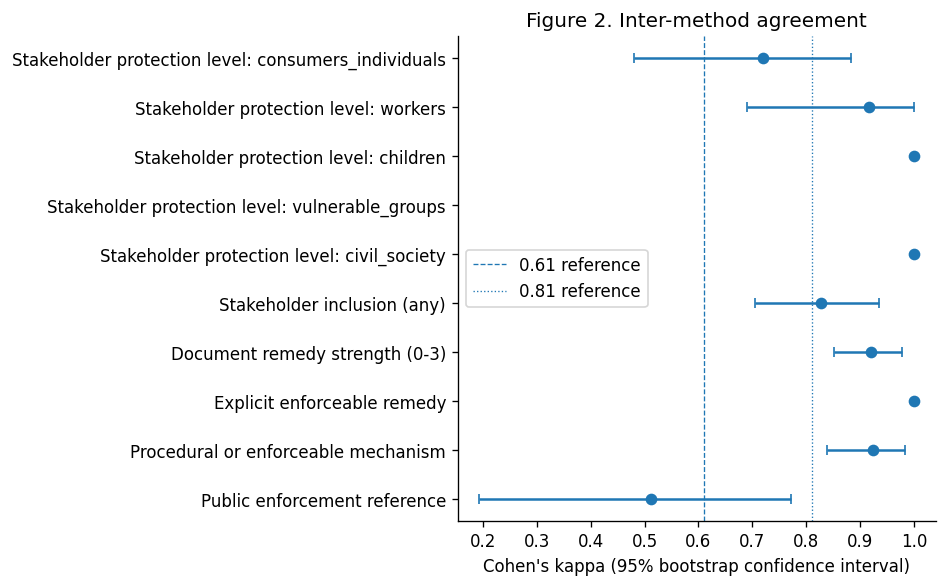

Conservative combined coding completed.
Policies with explicit enforceable-remedy indicators: 1
Policies with procedural or enforceable indicators: 28


In [5]:
def bootstrap_kappa(a, b, weights=None, n_boot=1000, seed=42):
    a = np.asarray(a)
    b = np.asarray(b)
    local_rng = np.random.default_rng(seed)
    estimates = []

    for _ in range(n_boot):
        idx = local_rng.integers(0, len(a), len(a))
        try:
            value = cohen_kappa_score(a[idx], b[idx], weights=weights)
            if np.isfinite(value):
                estimates.append(value)
        except Exception:
            continue

    if len(estimates) < 30:
        return np.nan, np.nan

    low, high = np.percentile(estimates, [2.5, 97.5])
    return low, high

agreement_rows = []

# Group-specific ordinal scores (0-3).
for group in GROUPS:
    a = pol[f"A_grp_{group}"]
    b = pol[f"B_grp_{group}"]
    kappa = cohen_kappa_score(a, b, weights="quadratic")
    low, high = bootstrap_kappa(a, b, weights="quadratic", seed=SEED + len(agreement_rows))
    agreement_rows.append([
        f"Stakeholder protection level: {group}",
        kappa, low, high, (a == b).mean()
    ])

# Document-level indicators and ordinal remedy score.
agreement_specs = [
    ("Stakeholder inclusion (any)", "A_inclusion", "B_inclusion", None),
    ("Document remedy strength (0-3)", "A_remedy", "B_remedy", "quadratic"),
    ("Explicit enforceable remedy", "A_enforceable_remedy", "B_enforceable_remedy", None),
    ("Procedural or enforceable mechanism", "A_procedural_or_enforceable", "B_procedural_or_enforceable", None),
    ("Public enforcement reference", "A_public_enforcement", "B_public_enforcement", None)
]

for label, col_a, col_b, weights in agreement_specs:
    a, b = pol[col_a], pol[col_b]
    kappa = cohen_kappa_score(a, b, weights=weights)
    low, high = bootstrap_kappa(a, b, weights=weights, seed=SEED + len(agreement_rows))
    agreement_rows.append([label, kappa, low, high, (a == b).mean()])

agreement_tbl = pd.DataFrame(
    agreement_rows,
    columns=["variable", "kappa", "ci_low", "ci_high", "raw_agreement"]
).round(3)

show(
    agreement_tbl,
    "Table 3. Inter-method agreement between rule-based procedure A and procedure B",
    "t03_inter_method_agreement",
    index=False
)

fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(agreement_tbl))
valid = agreement_tbl[["kappa", "ci_low", "ci_high"]].notna().all(axis=1)
ax.errorbar(
    agreement_tbl.loc[valid, "kappa"],
    y[valid.to_numpy()],
    xerr=[
        agreement_tbl.loc[valid, "kappa"] - agreement_tbl.loc[valid, "ci_low"],
        agreement_tbl.loc[valid, "ci_high"] - agreement_tbl.loc[valid, "kappa"]
    ],
    fmt="o", capsize=3
)
ax.axvline(0.61, linestyle="--", linewidth=0.8, label="0.61 reference")
ax.axvline(0.81, linestyle=":", linewidth=0.8, label="0.81 reference")
ax.set_yticks(y)
ax.set_yticklabels(agreement_tbl["variable"])
ax.invert_yaxis()
ax.set_xlabel("Cohen's kappa (95% bootstrap confidence interval)")
ax.set_title("Figure 2. Inter-method agreement")
ax.legend()
plt.tight_layout()
savefig("fig02_inter_method_agreement")

# Conservative combined coding: take the lower score across the two procedures.
# This is an analytical rule, not a human-validated ground truth.
pol["remedy"] = np.minimum(pol["A_remedy"], pol["B_remedy"])
pol["public_enforcement"] = np.minimum(
    pol["A_public_enforcement"], pol["B_public_enforcement"]
)

for group in GROUPS:
    pol[f"grp_{group}"] = np.minimum(
        pol[f"A_grp_{group}"], pol[f"B_grp_{group}"]
    )

pol["n_groups"] = (
    pol[[f"grp_{g}" for g in GROUPS]] > 0
).sum(axis=1)
pol["inclusion"] = (pol["n_groups"] > 0).astype(int)

# Separate outcomes: procedural safeguards and explicit individual remedies.
pol["procedural_protection"] = (pol["remedy"] == 2).astype(int)
pol["enforceable_remedy"] = (pol["remedy"] == 3).astype(int)
pol["procedural_or_enforceable"] = (pol["remedy"] >= 2).astype(int)

print("Conservative combined coding completed.")
print("Policies with explicit enforceable-remedy indicators:",
      int(pol["enforceable_remedy"].sum()))
print("Policies with procedural or enforceable indicators:",
      int(pol["procedural_or_enforceable"].sum()))

## 5. RQ1 – Stakeholder recognition, procedural protection and enforceable-right indicators

The table separates passive recognition, procedural protection and explicit enforceable-right/remedy indicators. The percentage of protected groups is calculated among policies in which the group is recognised.

**Table 4. RQ1 – Recognition and protection levels by stakeholder group (policy documents)**

,not_recognised,passive_recognition,procedural_protection,explicit_enforceable_right_remedy,pct_procedural_or_enforceable_of_recognised,pct_enforceable_of_recognised
stakeholder_group,,,,,,
consumers_individuals,233,5,6,0,54.5,0.0
workers,233,7,4,0,36.4,0.0
children,242,1,1,0,50.0,0.0
vulnerable_groups,244,0,0,0,NaN,NaN
civil_society,243,1,0,0,0.0,0.0


**Table 5 (Passive recognition) – Share of policy documents by binding status**

law_type,binding (hard law),non-binding (soft law)
stakeholder_group,,
children,0.012,0.000
civil_society,0.000,0.006
consumers_individuals,0.025,0.018
vulnerable_groups,0.000,0.000
workers,0.062,0.012


**Table 5 (Procedural protection) – Share of policy documents by binding status**

law_type,binding (hard law),non-binding (soft law)
stakeholder_group,,
children,0.012,0.000
civil_society,0.000,0.000
consumers_individuals,0.049,0.012
vulnerable_groups,0.000,0.000
workers,0.049,0.000


**Table 5 (Explicit enforceable-right/remedy indicator) – Share of policy documents by binding status**

law_type,binding (hard law),non-binding (soft law)
stakeholder_group,,
children,0.0,0.0
civil_society,0.0,0.0
consumers_individuals,0.0,0.0
vulnerable_groups,0.0,0.0
workers,0.0,0.0


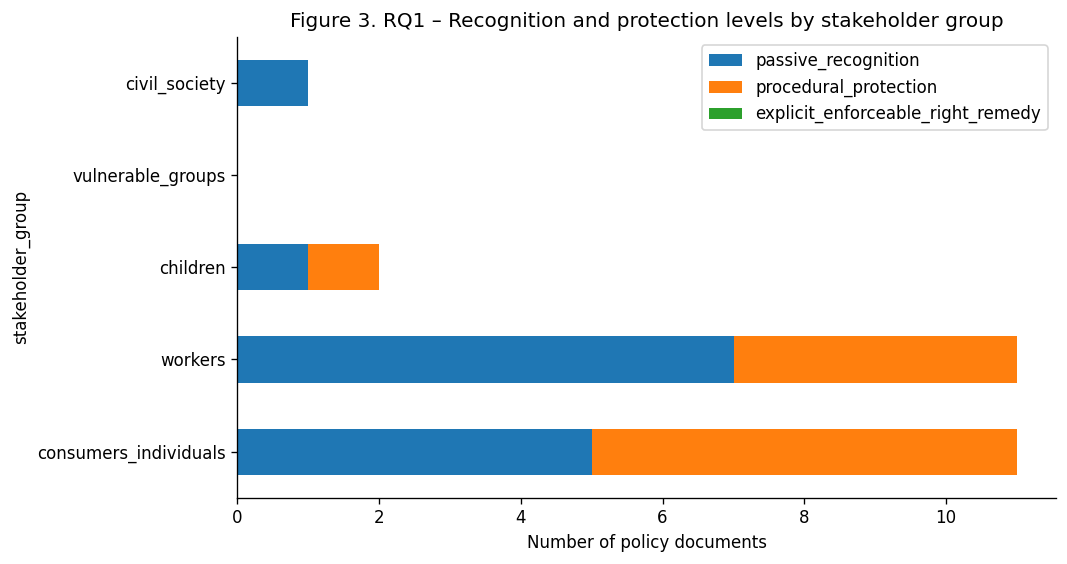

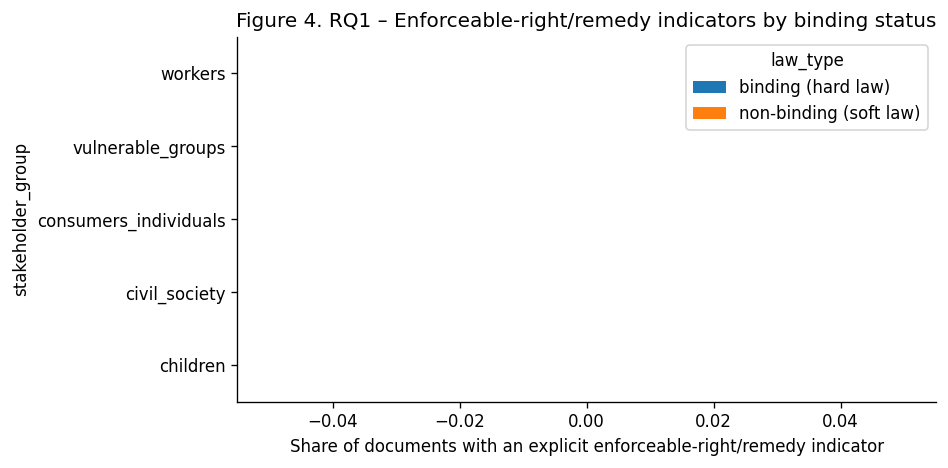

In [6]:
rq1_rows = []
for group in GROUPS:
    values = pol[f"grp_{group}"]
    recognised = int((values > 0).sum())
    protected = int((values >= 2).sum())
    enforceable = int((values == 3).sum())

    rq1_rows.append({
        "stakeholder_group": group,
        "not_recognised": int((values == 0).sum()),
        "passive_recognition": int((values == 1).sum()),
        "procedural_protection": int((values == 2).sum()),
        "explicit_enforceable_right_remedy": enforceable,
        "pct_procedural_or_enforceable_of_recognised":
            round(100 * protected / recognised, 1) if recognised else np.nan,
        "pct_enforceable_of_recognised":
            round(100 * enforceable / recognised, 1) if recognised else np.nan
    })

rq1 = pd.DataFrame(rq1_rows).set_index("stakeholder_group")
show(
    rq1,
    "Table 4. RQ1 – Recognition and protection levels by stakeholder group (policy documents)",
    "t04_rq1_recognition_protection"
)

# Distribution of each protection level by binding status.
rq1_binding_rows = []
for law_type, subset in pol.groupby("law_type", dropna=False):
    for group in GROUPS:
        values = subset[f"grp_{group}"]
        rq1_binding_rows.append({
            "law_type": law_type,
            "stakeholder_group": group,
            "n_policies": len(subset),
            "passive_share": (values == 1).mean(),
            "procedural_share": (values == 2).mean(),
            "enforceable_share": (values == 3).mean()
        })

rq1_binding = pd.DataFrame(rq1_binding_rows)
for variable, label, filename in [
    ("passive_share", "Passive recognition", "t05a"),
    ("procedural_share", "Procedural protection", "t05b"),
    ("enforceable_share", "Explicit enforceable-right/remedy indicator", "t05c")
]:
    pivot = rq1_binding.pivot(
        index="stakeholder_group", columns="law_type", values=variable
    ).round(3)
    show(
        pivot,
        f"Table 5 ({label}) – Share of policy documents by binding status",
        f"{filename}_rq1_{variable}"
    )

ax = rq1[[
    "passive_recognition",
    "procedural_protection",
    "explicit_enforceable_right_remedy"
]].plot(kind="barh", stacked=True, figsize=(9, 4.8))
ax.set_xlabel("Number of policy documents")
ax.set_title("Figure 3. RQ1 – Recognition and protection levels by stakeholder group")
plt.tight_layout()
savefig("fig03_rq1_recognition_protection")

enforceable_pivot = rq1_binding.pivot(
    index="stakeholder_group", columns="law_type", values="enforceable_share"
)
ax = enforceable_pivot.plot(kind="barh", figsize=(8, 4))
ax.set_xlabel("Share of documents with an explicit enforceable-right/remedy indicator")
ax.set_title("Figure 4. RQ1 – Enforceable-right/remedy indicators by binding status")
plt.tight_layout()
savefig("fig04_rq1_enforceable_by_binding")

## 6. RQ2 – Binding and non-binding accountability structures

The document-level remedy scale distinguishes 0 = none, 1 = symbolic/aspirational, 2 = procedural safeguard and 3 = explicit individual right/remedy indicator. Public sanctions and penalties are tabulated separately and are not automatically treated as individual remedies.

**Table 6 – remedy by binding status (row shares; Chi-square (sparse expected cells; interpret cautiously), p = 2.584e-06)**

remedy,0,1,2,3
law_type,,,,
binding (hard law),0.444,0.321,0.235,0.000
non-binding (soft law),0.325,0.620,0.049,0.006


**Table 6 – procedural_protection by binding status (row shares; Fisher exact, p = 3.974e-05)**

procedural_protection,0,1
law_type,,
binding (hard law),0.765,0.235
non-binding (soft law),0.951,0.049


**Table 6 – enforceable_remedy by binding status (row shares; Fisher exact, p = 1)**

enforceable_remedy,0,1
law_type,,
binding (hard law),1.000,0.000
non-binding (soft law),0.994,0.006


... (4 outputs left out)

**Table 6 – inclusion by binding status (row shares; Fisher exact, p = 0.003305)**

inclusion,0,1
law_type,,
binding (hard law),0.827,0.173
non-binding (soft law),0.951,0.049


**Table 7 – Obligation categories by binding status (chi-square p = 0.31; sparse expected counts; descriptive interpretation preferred)**

is_binding,False,True
category,,
accuracy_robustness_security,0.00,0.031
ai_literacy,0.00,0.010
conformity_assessment,0.00,0.010
copyright_training_data,0.00,0.010
data_governance,0.05,0.021
governance_accountability,0.40,0.113
human_oversight,0.15,0.062
impact_assessment,0.10,0.052
incident_handling,0.00,0.072


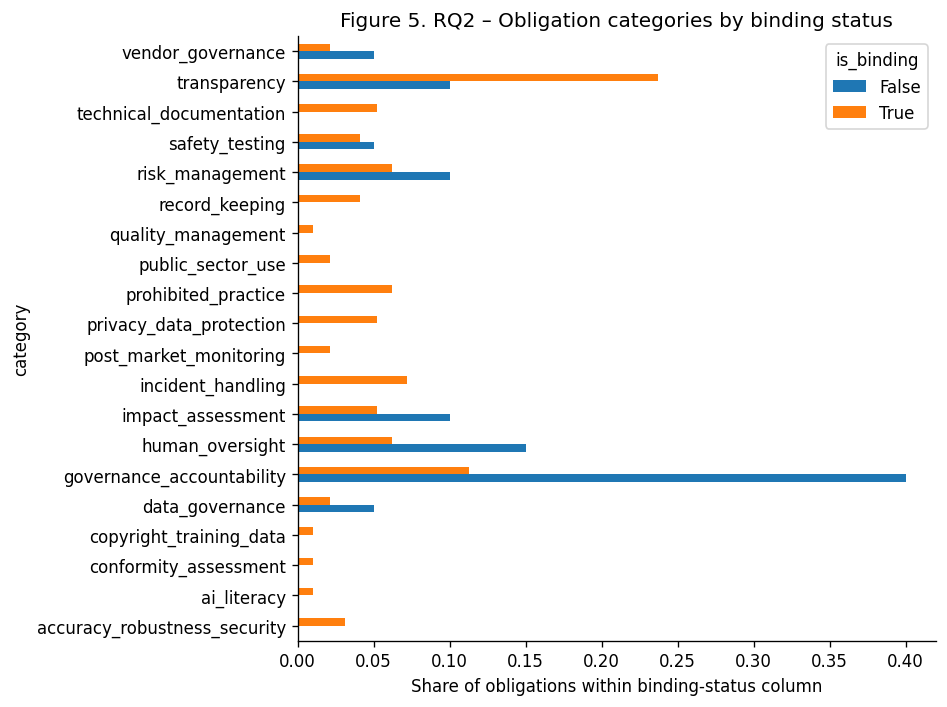

**Table 8 – Recorded accountability-related obligation categories by binding status**

,share_accountability_mechanisms,n_accountability_obligations,n_obligations
is_binding,,,
False,0.750,15,20
True,0.495,48,97


**Table 9 – Descriptive summary by document format and binding status**

n_policies  mean_remedy_indicator  pct_inclusion  pct_procedural  pct_enforceable  mean_obligations
format        law_type                                                                                                                   
consultation  non-binding (soft law)           4                  0.750          0.000           0.250            0.000             0.000
policy        binding (hard law)               6                  0.333          0.000           0.000            0.000             0.000
              non-binding (soft law)          24                  0.875          0.083           0.042            0.042             0.250
soft_guidance binding (hard law)               4                  0.500          0.250           0.000            0.000             0.500
              non-binding (soft law)          31                  1.032          0.194           0.161            0.000             0.516
statute       binding (hard law)              71                  0.845          0.183           0.268            0.000             1.296
              non-binding (soft law)           5                  0.800          0.000           0.200            0.000             0.000
strategy      non-binding (soft law)          99                  0.606          0.000           0.000            0.000             0.010

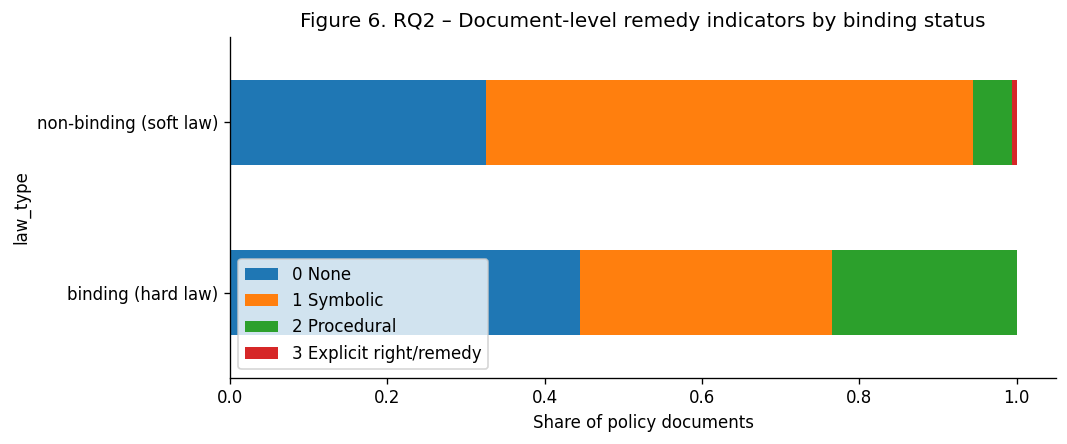

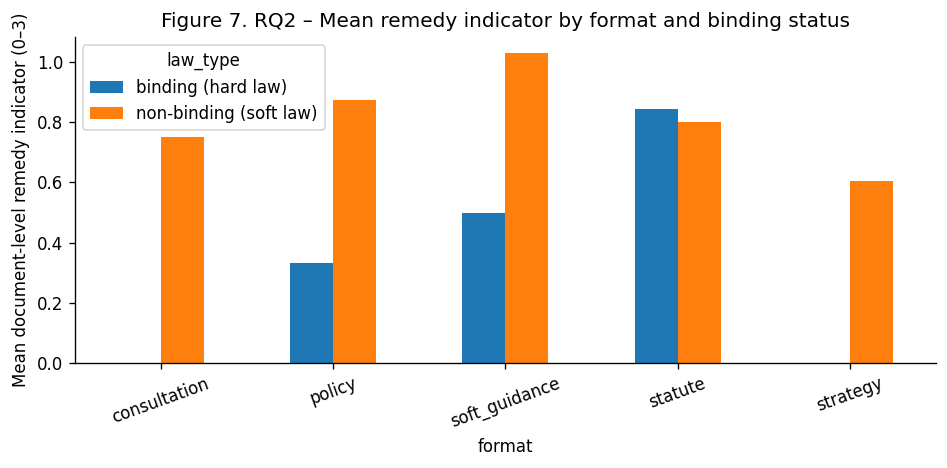

In [7]:
def cross_tab_test(data, row, col):
    table = pd.crosstab(data[row], data[col])
    if table.shape == (2, 2):
        _, p_value = stats.fisher_exact(table)
        test_name = "Fisher exact"
    else:
        _, p_value, _, expected = stats.chi2_contingency(table)
        if (expected < 5).any():
            test_name = "Chi-square (sparse expected cells; interpret cautiously)"
        else:
            test_name = "Chi-square"
    return table, test_name, p_value

for variable in [
    "remedy",
    "procedural_protection",
    "enforceable_remedy",
    "procedural_or_enforceable",
    "public_enforcement",
    "inclusion"
]:
    table, test_name, p_value = cross_tab_test(pol, "law_type", variable)
    proportions = pd.crosstab(
        pol["law_type"], pol[variable], normalize="index"
    ).round(3)
    show(
        proportions,
        f"Table 6 – {variable} by binding status (row shares; {test_name}, p = {p_value:.4g})",
        f"t06_rq2_{variable}_by_law_type"
    )

# Obligation category by binding status.
obl_j = obl.merge(
    pol[["slug", "law_type", "format", "tier"]].rename(columns={"slug": "policy"}),
    on="policy",
    how="left",
    validate="many_to_one"
)

if "is_binding" not in obl_j.columns:
    raise KeyError("The obligations table must contain is_binding.")

cat_ct = pd.crosstab(obl_j["category"], obl_j["is_binding"])
cat_share = (cat_ct / cat_ct.sum()).round(3)

chi2, p_value, dof, expected = stats.chi2_contingency(cat_ct)
sparse_note = "sparse expected counts; descriptive interpretation preferred" if (expected < 5).any() else "expected counts adequate"

show(
    cat_share,
    f"Table 7 – Obligation categories by binding status (chi-square p = {p_value:.3g}; {sparse_note})",
    "t07_rq2_obligation_categories_by_binding"
)

cat_share.plot(kind="barh", figsize=(8, 6))
plt.xlabel("Share of obligations within binding-status column")
plt.title("Figure 5. RQ2 – Obligation categories by binding status")
plt.tight_layout()
savefig("fig05_rq2_obligation_categories")

ACCOUNTABILITY_CATEGORIES = [
    "governance_accountability", "human_oversight", "risk_management",
    "impact_assessment", "incident_handling", "record_keeping",
    "post_market_monitoring", "conformity_assessment",
    "quality_management", "technical_documentation"
]
obl_j["accountability_category"] = obl_j["category"].isin(ACCOUNTABILITY_CATEGORIES)
accountability_summary = (
    obl_j.groupby("is_binding")["accountability_category"]
         .agg(["mean", "sum", "count"])
         .rename(columns={
             "mean": "share_accountability_mechanisms",
             "sum": "n_accountability_obligations",
             "count": "n_obligations"
         }).round(3)
)
show(
    accountability_summary,
    "Table 8 – Recorded accountability-related obligation categories by binding status",
    "t08_rq2_accountability_share"
)

stratified = (
    pol.groupby(["format", "law_type"], dropna=False)
       .agg(
           n_policies=("slug", "count"),
           mean_remedy_indicator=("remedy", "mean"),
           pct_inclusion=("inclusion", "mean"),
           pct_procedural=("procedural_protection", "mean"),
           pct_enforceable=("enforceable_remedy", "mean"),
           mean_obligations=("n_obligations", "mean")
       ).round(3)
)
show(
    stratified,
    "Table 9 – Descriptive summary by document format and binding status",
    "t09_rq2_stratified_summary"
)

remedy_distribution = pd.crosstab(
    pol["law_type"], pol["remedy"], normalize="index"
).reindex(columns=[0, 1, 2, 3], fill_value=0)
remedy_distribution.columns = [
    "0 None", "1 Symbolic", "2 Procedural", "3 Explicit right/remedy"
]
remedy_distribution.plot(kind="barh", stacked=True, figsize=(9, 3.8))
plt.xlabel("Share of policy documents")
plt.title("Figure 6. RQ2 – Document-level remedy indicators by binding status")
plt.tight_layout()
savefig("fig06_rq2_remedy_by_binding")

format_plot = stratified.reset_index().pivot(
    index="format", columns="law_type", values="mean_remedy_indicator"
)
format_plot.plot(kind="bar", figsize=(8, 4))
plt.ylabel("Mean document-level remedy indicator (0–3)")
plt.title("Figure 7. RQ2 – Mean remedy indicator by format and binding status")
plt.xticks(rotation=20)
plt.tight_layout()
savefig("fig07_rq2_stratified_remedy")

## 7. RQ3 – Regression: stakeholder inclusion and explicit enforceable-right/remedy indicators

**Primary outcome:** `enforceable_remedy` = 1 only when the conservative combined document-level code identifies an explicit individual right/remedy indicator (score 3).

**Secondary outcome:** `procedural_or_enforceable` = 1 when the document contains either a procedural safeguard (score 2) or an explicit individual right/remedy indicator (score 3).

The models control for document format and jurisdictional tier. The analysis is exploratory and estimates document-level associations, not causal effects. Stakeholder inclusion and remedy indicators are both derived from the same policy text; therefore, the relationship may partly reflect shared document content. A document-level association does not establish that the identified remedy specifically protects the stakeholder group mentioned.

A logistic regression is only fitted when there are at least 10 positive and 10 negative outcome cases and the model converges without detected separation problems. If these conditions are not met, the notebook reports descriptive results rather than forcing a regression.

Complete-case regression N: 244
enforceable_remedy: non-events=243, events=1, N=244
Regression skipped: fewer than 10 cases in one outcome category. Report descriptive results instead.
enforceable_remedy: non-events=243, events=1, N=244
Regression skipped: fewer than 10 cases in one outcome category. Report descriptive results instead.
procedural_or_enforceable: non-events=216, events=28, N=244


**Table 10. RQ3 – Logistic regression results (odds ratios, 95% confidence intervals, HC1 SE)**

,coefficient,odds_ratio,OR_CI_low,OR_CI_high,p_value,N
model,,,,,,
"Secondary: procedural or enforceable, stakeholder inclusion",1.6428,5.1695,1.7,15.7201,0.0038,244


**Secondary model: procedural or enforceable outcome**

<class 'statsmodels.iolib.summary.Summary'>
"""
                               Logit Regression Results                              
=====================================================================================
Dep. Variable:     procedural_or_enforceable   No. Observations:                  244
Model:                                 Logit   Df Residuals:                      238
Method:                                  MLE   Df Model:                            5
Date:                       Mon, 02 Nov 2026   Pseudo R-squ.:                  0.2218
Time:                               14:33:37   Log-Likelihood:                -67.666
converged:                              True   LL-Null:                       -86.947
Covariance Type:                         HC1   LLR p-value:                 2.909e-07
=================================================================================================
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept                        -2.3696      0.649     -3.649      0.000      -3.642      -1.097
C(format3)[T.statute]             0.8847      0.674      1.314      0.189      -0.435       2.205
C(format3)[T.strategy_policy]    -1.4907      0.861     -1.731      0.083      -3.179       0.197
C(tier)[T.state]                  0.1717      0.489      0.351      0.725      -0.787       1.130
C(tier)[T.supranational]          0.2818      0.885      0.318      0.750      -1.452       2.016
inclusion                         1.6428      0.567      2.895      0.004       0.531       2.755
=================================================================================================
"""

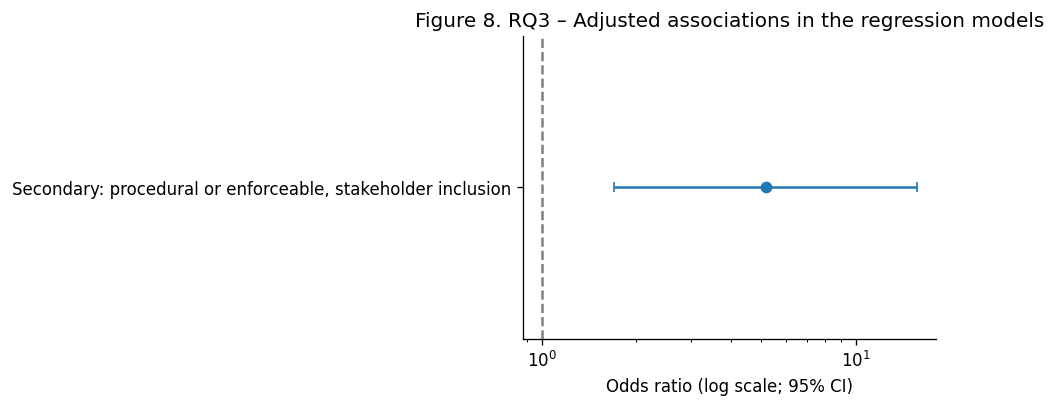

enforceable_remedy: non-events=81, events=0, N=81
Regression skipped: fewer than 10 cases in one outcome category. Report descriptive results instead.


**Table 13. RQ3 – Exploratory ordered-logit robustness model**

,coefficient,odds_ratio,p_value
inclusion,2.398,11.0016,0.0


In [8]:
# Prepare complete-case regression data.
d = pol.dropna(subset=["format3", "tier"]).copy()
d["format3"] = d["format3"].astype("category")
d["tier"] = d["tier"].astype("category")

print("Complete-case regression N:", len(d))

def outcome_counts(data, outcome):
    counts = data[outcome].value_counts().reindex([0, 1], fill_value=0)
    return int(counts.loc[0]), int(counts.loc[1])

def fit_checked_logit(formula, data, outcome, min_events=10):
    """Fit conventional logit only when event counts are adequate and model converges."""
    n0, n1 = outcome_counts(data, outcome)
    print(f"{outcome}: non-events={n0}, events={n1}, N={len(data)}")

    if min(n0, n1) < min_events:
        print(
            f"Regression skipped: fewer than {min_events} cases in one outcome category. "
            "Report descriptive results instead."
        )
        return None

    try:
        model = smf.logit(formula, data=data).fit(
            disp=False, cov_type="HC1", maxiter=200
        )
        converged = bool(model.mle_retvals.get("converged", False))
        if not converged:
            print("Regression skipped: optimizer did not converge.")
            return None

        # Check for very large coefficients, which may signal quasi/complete separation.
        non_intercept = model.params.drop("Intercept", errors="ignore")
        if (non_intercept.abs() > 10).any():
            print("Regression skipped: very large coefficients suggest separation.")
            return None

        return model
    except Exception as error:
        print("Regression could not be estimated:", repr(error))
        print("Do not interpret a failed or separated model as valid evidence.")
        return None

def model_result_row(model, term, label):
    if model is None or term not in model.params.index:
        return None
    ci = model.conf_int().loc[term]
    return {
        "model": label,
        "coefficient": model.params[term],
        "odds_ratio": np.exp(model.params[term]),
        "OR_CI_low": np.exp(ci.iloc[0]),
        "OR_CI_high": np.exp(ci.iloc[1]),
        "p_value": model.pvalues[term],
        "N": int(model.nobs)
    }

# Primary specification: explicit enforceable right/remedy indicator.
m_primary_inclusion = fit_checked_logit(
    "enforceable_remedy ~ inclusion + C(format3) + C(tier)",
    d, "enforceable_remedy"
)

m_primary_group_count = fit_checked_logit(
    "enforceable_remedy ~ n_groups + C(format3) + C(tier)",
    d, "enforceable_remedy"
)

# Secondary specification: procedural safeguard OR enforceable remedy.
m_secondary = fit_checked_logit(
    "procedural_or_enforceable ~ inclusion + C(format3) + C(tier)",
    d, "procedural_or_enforceable"
)

models = [
    (m_primary_inclusion, "inclusion", "Primary: enforceable remedy, stakeholder inclusion"),
    (m_primary_group_count, "n_groups", "Primary: enforceable remedy, number of groups"),
    (m_secondary, "inclusion", "Secondary: procedural or enforceable, stakeholder inclusion")
]

result_rows = []
for model, term, label in models:
    row = model_result_row(model, term, label)
    if row is not None:
        result_rows.append(row)

if result_rows:
    regression_results = pd.DataFrame(result_rows).set_index("model").round(4)
    show(
        regression_results,
        "Table 10. RQ3 – Logistic regression results (odds ratios, 95% confidence intervals, HC1 SE)",
        "t10_rq3_regression_results"
    )
else:
    print("No regression model met the pre-specified estimation checks.")
    print("Use the descriptive outcome frequencies and avoid regression claims.")

# Display full model summaries where models were successfully estimated.
for label, model in [
    ("Primary model: inclusion", m_primary_inclusion),
    ("Primary model: number of stakeholder groups", m_primary_group_count),
    ("Secondary model: procedural or enforceable outcome", m_secondary)
]:
    if model is not None:
        display(Markdown(f"**{label}**"))
        display(model.summary())

# Forest plot for estimated stakeholder-inclusion / group-count terms.
plot_rows = []
for model, term, label in models:
    row = model_result_row(model, term, label)
    if row is not None:
        plot_rows.append(row)

if plot_rows:
    plot_df = pd.DataFrame(plot_rows)
    y = np.arange(len(plot_df))
    fig, ax = plt.subplots(figsize=(8, max(3.5, 0.7 * len(plot_df))))
    ax.errorbar(
        plot_df["odds_ratio"], y,
        xerr=[
            plot_df["odds_ratio"] - plot_df["OR_CI_low"],
            plot_df["OR_CI_high"] - plot_df["odds_ratio"]
        ],
        fmt="o", capsize=3
    )
    ax.axvline(1, color="grey", linestyle="--")
    ax.set_xscale("log")
    ax.set_yticks(y)
    ax.set_yticklabels(plot_df["model"])
    ax.invert_yaxis()
    ax.set_xlabel("Odds ratio (log scale; 95% CI)")
    ax.set_title("Figure 8. RQ3 – Adjusted associations in the regression models")
    plt.tight_layout()
    savefig("fig08_rq3_regression_forest")

# Adjusted predicted probabilities for the primary model, only if it was estimable.
if m_primary_inclusion is not None:
    probability_rows = []
    for fmt in d["format3"].cat.categories:
        base = d[d["format3"] == fmt].copy()
        if base.empty:
            continue
        for inclusion_value in [0, 1]:
            scenario = base.copy()
            scenario["inclusion"] = inclusion_value
            probability_rows.append({
                "format3": str(fmt),
                "inclusion": inclusion_value,
                "mean_predicted_probability":
                    float(m_primary_inclusion.predict(scenario).mean())
            })

    predicted_probabilities = pd.DataFrame(probability_rows)
    if not predicted_probabilities.empty:
        probability_pivot = predicted_probabilities.pivot(
            index="format3", columns="inclusion",
            values="mean_predicted_probability"
        ).round(3)
        show(
            probability_pivot,
            "Table 11. RQ3 – Adjusted predicted probability of an explicit enforceable-remedy indicator",
            "t11_rq3_predicted_probabilities"
        )
        probability_pivot.plot(kind="bar", figsize=(7, 4))
        plt.ylabel("Mean predicted probability")
        plt.xlabel("Document format")
        plt.title("Figure 9. RQ3 – Predicted probability by format and stakeholder inclusion")
        plt.legend(["No stakeholder inclusion", "Stakeholder inclusion"])
        plt.xticks(rotation=15)
        plt.tight_layout()
        savefig("fig09_rq3_predicted_probabilities")

# Binding-only sensitivity analysis, with the same event-count safeguards.
binding_data = d[d["is_binding"].fillna(False).astype(bool)].copy()
m_binding = fit_checked_logit(
    "enforceable_remedy ~ inclusion + C(tier)",
    binding_data, "enforceable_remedy"
)
binding_row = model_result_row(
    m_binding, "inclusion", "Binding instruments only"
)
if binding_row is not None:
    binding_sensitivity = pd.DataFrame([binding_row]).set_index("model").round(4)
    show(
        binding_sensitivity,
        "Table 12. RQ3 – Sensitivity analysis restricted to binding instruments",
        "t12_rq3_binding_sensitivity"
    )

# Optional ordinal robustness model, only if all remedy levels are represented.
try:
    from statsmodels.miscmodels.ordinal_model import OrderedModel

    ordinal_data = d[["remedy", "inclusion", "format3", "tier"]].dropna().copy()
    ordinal_data["remedy"] = ordinal_data["remedy"].astype(int)
    if ordinal_data["remedy"].nunique() >= 3:
        X = pd.get_dummies(
            ordinal_data[["inclusion", "format3", "tier"]],
            drop_first=True, dtype=float
        )
        ordinal_model = OrderedModel(
            ordinal_data["remedy"], X, distr="logit"
        ).fit(method="bfgs", disp=False)

        if "inclusion" in ordinal_model.params.index:
            ordinal_result = pd.DataFrame({
                "coefficient": [ordinal_model.params["inclusion"]],
                "odds_ratio": [np.exp(ordinal_model.params["inclusion"])],
                "p_value": [ordinal_model.pvalues["inclusion"]]
            }, index=["inclusion"]).round(4)
            show(
                ordinal_result,
                "Table 13. RQ3 – Exploratory ordered-logit robustness model",
                "t13_rq3_ordered_logit"
            )
    else:
        print("Ordered logit skipped: fewer than three remedy levels are represented.")
except Exception as error:
    print("Ordered-logit robustness model skipped:", repr(error))

## 8. RQ4 – Actor references in AI governance obligations and implementation records

The actor regexes identify **references to actors** in obligation descriptions. A textual reference is not automatically evidence that the actor has a legally assigned duty. The results are therefore descriptive actor-reference patterns, not a verified measure of legal responsibility or regulatory burden.

**Important denominator note:** Actor categories are not mutually exclusive. One obligation may mention more than one actor. Consequently, actor-reference counts and percentages can sum to more than the total number of obligations and 100%, respectively.

**Table 14. RQ4 – Distribution of actor references across recorded obligations**

,n_obligations_mentioning_actor,n_binding_obligations_mentioning_actor,pct_of_all_obligations_mentioning_actor
provider_developer,51,49,43.6
deployer_user_organisation,59,52,50.4
importer_distributor,8,8,6.8
public_authority,39,34,33.3
gpai_frontier,23,22,19.7


Total recorded obligations: 117
Total actor references across categories: 180
Actor categories are overlapping; totals may exceed the number of obligations.


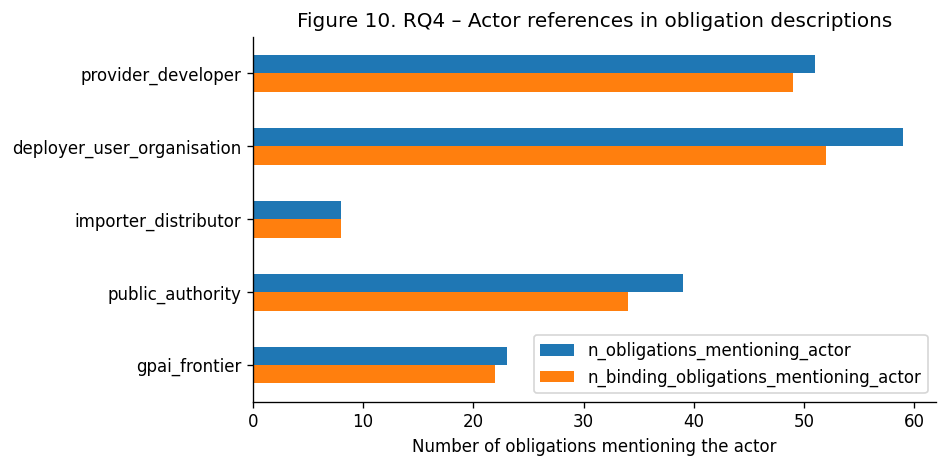

**Table 15. RQ4 – Operational/technical category share among obligations mentioning each actor**

,n_obligations_mentioning_actor,share_in_operational_technical_categories
actor_reference,,
provider_developer,51,0.392
deployer_user_organisation,59,0.220
importer_distributor,8,0.250
public_authority,39,0.282
gpai_frontier,23,0.304


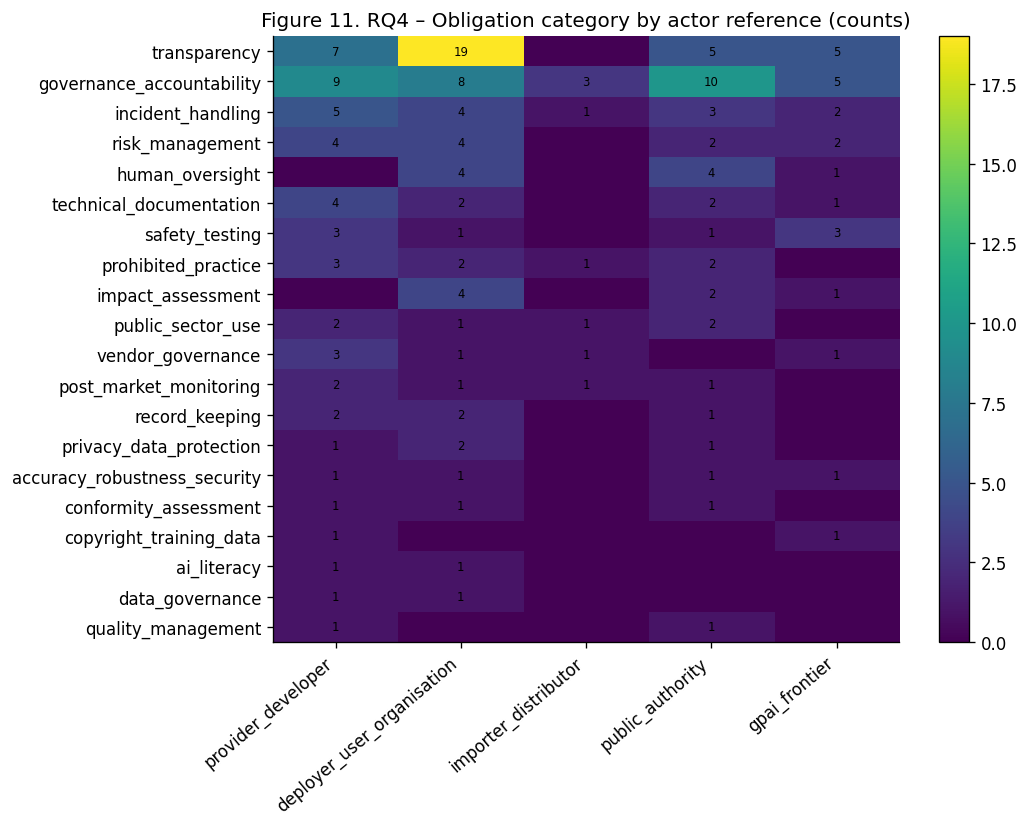

**Table 16. RQ4 – Obligation category by actor reference (counts)**

,provider_developer,deployer_user_organisation,importer_distributor,public_authority,gpai_frontier
category,,,,,
transparency,7,19,0,5,5
governance_accountability,9,8,3,10,5
incident_handling,5,4,1,3,2
risk_management,4,4,0,2,2
human_oversight,0,4,0,4,1
technical_documentation,4,2,0,2,1
safety_testing,3,1,0,1,3
prohibited_practice,3,2,1,2,0
impact_assessment,0,4,0,2,1


**Table 17. RQ4 – Recorded obligations by jurisdiction (top share = 0.376; HHI = 0.184)**

,n_obligations,share_of_recorded_obligations
jurisdiction,,
eu,44,0.376
us-colorado,15,0.128
south-korea,9,0.077
uk,7,0.060
us,7,0.060
us-texas,7,0.060
singapore,6,0.051
us-new-york,5,0.043
us-california,5,0.043


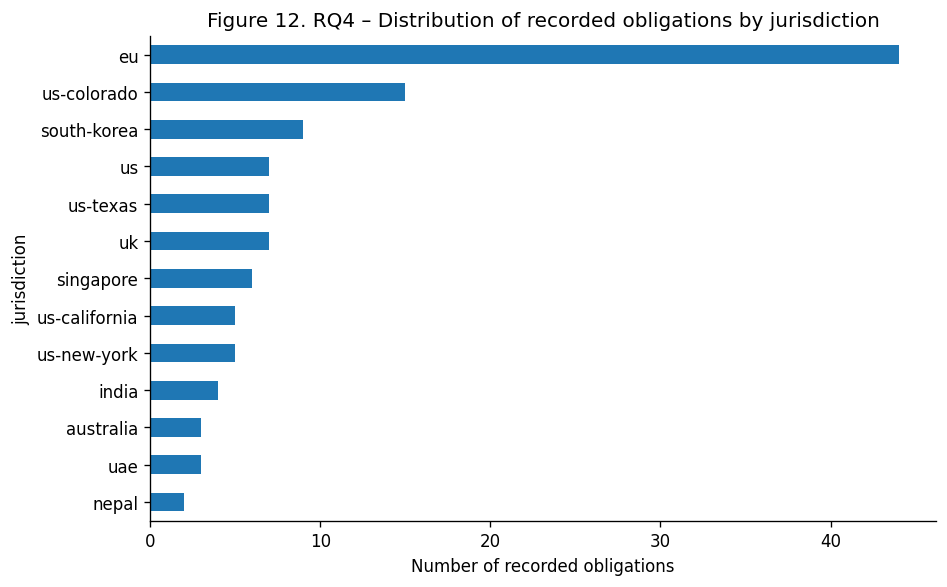

**Table 18. RQ4 – Implementation records (descriptive only; n = 8)**

,slug,kind,status,source_tier,published_on,confidence_level
0,eu-ai-act-ai-generated-content-marking-code,code_of_practice,unverified,4,NaT,unavailable
1,eu-ai-act-gpai-code-of-practice,code_of_practice,published,2,2025-07-10,medium
2,eu-ai-act-guidelines-on-prohibited-practices,guidelines,published,2,2025-02-04,medium
3,eu-ai-act-high-risk-classification-guidelines,guidelines,unverified,4,NaT,unavailable
4,eu-ai-act-training-content-summary-template,template,unverified,4,NaT,unavailable
5,iso-iec-42001-2023,iso_work_item,published,1,2023-12-18,medium
6,iso-iec-42005-2025,iso_work_item,published,1,2025-01-01,medium
7,iso-iec-42006-2025,iso_work_item,published,1,2025-01-01,medium


**Table 19. RQ4 – Implementation records by instrument type and status**

status,published,unverified
kind,,
code_of_practice,1,1
guidelines,1,1
iso_work_item,3,0
template,0,1


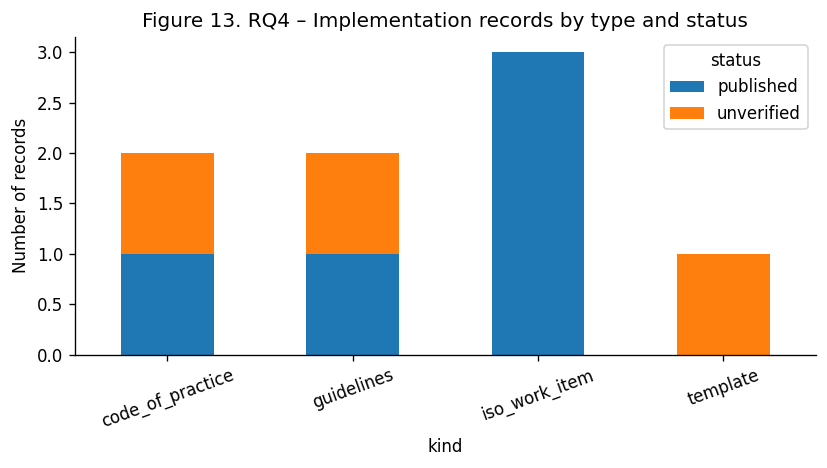

In [9]:
ACTORS = {
    "provider_developer": r"\b(providers?|developers?|manufacturers?|vendors?|suppliers?)\b",
    "deployer_user_organisation": r"\b(deployers?|operators?|users? of|organi[sz]ations?|businesses|companies|employers?|controllers?|processors?)\b",
    "importer_distributor": r"\b(importers?|distributors?|authori[sz]ed representatives?)\b",
    "public_authority": r"\b(public (authorit|bod|sector)\w*|government|agenc(y|ies)|regulators?|ministr\w+|authorit(y|ies))\b",
    "gpai_frontier": r"\b(general[- ]purpose|frontier|foundation model|systemic risk|high-impact)\b"
}

# Apply actor-reference patterns to obligation descriptions.
for actor, pattern in ACTORS.items():
    obl[f"actor_ref_{actor}"] = (
        obl["obl_text"].fillna("").astype(str).str.contains(
            pattern, flags=re.I, regex=True
        )
    )

actor_cols = [f"actor_ref_{actor}" for actor in ACTORS]
obl["n_actor_categories_referenced"] = obl[actor_cols].sum(axis=1)
obl["no_actor_reference_detected"] = obl["n_actor_categories_referenced"].eq(0)

actor_reference_table = pd.DataFrame({
    "n_obligations_mentioning_actor": obl[actor_cols].sum(),
    "n_binding_obligations_mentioning_actor":
        obl.loc[obl["is_binding"].fillna(False).astype(bool), actor_cols].sum(),
    "pct_of_all_obligations_mentioning_actor":
        (obl[actor_cols].mean() * 100).round(1)
})
actor_reference_table.index = [
    name.replace("actor_ref_", "") for name in actor_reference_table.index
]

show(
    actor_reference_table,
    "Table 14. RQ4 – Distribution of actor references across recorded obligations",
    "t14_rq4_actor_references"
)

print("Total recorded obligations:", len(obl))
print("Total actor references across categories:", int(obl[actor_cols].to_numpy().sum()))
print("Actor categories are overlapping; totals may exceed the number of obligations.")

ax = actor_reference_table[
    ["n_obligations_mentioning_actor", "n_binding_obligations_mentioning_actor"]
].plot(kind="barh", figsize=(8, 4))
ax.set_xlabel("Number of obligations mentioning the actor")
ax.set_title("Figure 10. RQ4 – Actor references in obligation descriptions")
ax.invert_yaxis()
plt.tight_layout()
savefig("fig10_rq4_actor_references")

# Operational/technical obligation categories by actor reference.
OPERATIONAL_CATEGORIES = [
    "technical_documentation", "safety_testing", "record_keeping",
    "accuracy_robustness_security", "conformity_assessment",
    "post_market_monitoring", "quality_management",
    "data_governance", "incident_handling"
]
obl["operational_technical_category"] = obl["category"].isin(
    OPERATIONAL_CATEGORIES
)

actor_operational_rows = []
for actor, column in zip(ACTORS.keys(), actor_cols):
    subset = obl[obl[column]]
    actor_operational_rows.append({
        "actor_reference": actor,
        "n_obligations_mentioning_actor": len(subset),
        "share_in_operational_technical_categories":
            subset["operational_technical_category"].mean()
            if len(subset) else np.nan
    })

actor_operational_table = pd.DataFrame(actor_operational_rows).set_index(
    "actor_reference"
).round(3)

show(
    actor_operational_table,
    "Table 15. RQ4 – Operational/technical category share among obligations mentioning each actor",
    "t15_rq4_actor_operational_share"
)

# Actor-reference by obligation-category counts. An obligation can appear in several actor columns.
heat = pd.DataFrame({
    actor: obl.loc[obl[column]].groupby("category").size()
    for actor, column in zip(ACTORS.keys(), actor_cols)
}).fillna(0).astype(int)

if not heat.empty:
    heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(9, 7))
    image = ax.imshow(heat.values, aspect="auto")
    ax.set_xticks(range(heat.shape[1]))
    ax.set_xticklabels(heat.columns, rotation=40, ha="right")
    ax.set_yticks(range(heat.shape[0]))
    ax.set_yticklabels(heat.index)
    for row_idx in range(heat.shape[0]):
        for col_idx in range(heat.shape[1]):
            if heat.iloc[row_idx, col_idx] > 0:
                ax.text(
                    col_idx, row_idx, heat.iloc[row_idx, col_idx],
                    ha="center", va="center", fontsize=7
                )
    ax.set_title("Figure 11. RQ4 – Obligation category by actor reference (counts)")
    plt.colorbar(image, ax=ax)
    plt.tight_layout()
    savefig("fig11_rq4_actor_reference_category")

show(
    heat,
    "Table 16. RQ4 – Obligation category by actor reference (counts)",
    "t16_rq4_actor_reference_category"
)

# Distribution of recorded obligations by jurisdiction.
jurisdiction_counts = obl["jurisdiction"].fillna("Unknown").value_counts()
jurisdiction_shares = jurisdiction_counts / jurisdiction_counts.sum()
jurisdiction_table = pd.DataFrame({
    "n_obligations": jurisdiction_counts,
    "share_of_recorded_obligations": jurisdiction_shares.round(3)
})

top_share = float(jurisdiction_shares.iloc[0]) if len(jurisdiction_shares) else np.nan
hhi = float((jurisdiction_shares ** 2).sum()) if len(jurisdiction_shares) else np.nan

show(
    jurisdiction_table,
    f"Table 17. RQ4 – Recorded obligations by jurisdiction (top share = {top_share:.3f}; HHI = {hhi:.3f})",
    "t17_rq4_obligations_by_jurisdiction"
)

jurisdiction_table["n_obligations"].sort_values().plot(
    kind="barh", figsize=(8, 5)
)
plt.xlabel("Number of recorded obligations")
plt.title("Figure 12. RQ4 – Distribution of recorded obligations by jurisdiction")
plt.tight_layout()
savefig("fig12_rq4_obligations_by_jurisdiction")

# Implementation records: only eight rows, so report descriptively.
if "published_on" in imp.columns:
    imp["published_on"] = pd.to_datetime(imp["published_on"], errors="coerce")

implementation_columns = [
    col for col in [
        "slug", "kind", "status", "source_tier",
        "published_on", "confidence_level"
    ] if col in imp.columns
]

show(
    imp[implementation_columns],
    f"Table 18. RQ4 – Implementation records (descriptive only; n = {len(imp)})",
    "t18_rq4_implementation_records",
    index=False
)

if {"kind", "status"}.issubset(imp.columns):
    implementation_cross_tab = imp.groupby(
        ["kind", "status"], dropna=False
    ).size().unstack(fill_value=0)

    show(
        implementation_cross_tab,
        "Table 19. RQ4 – Implementation records by instrument type and status",
        "t19_rq4_implementation_kind_status"
    )

    implementation_cross_tab.plot(kind="bar", stacked=True, figsize=(7, 4))
    plt.ylabel("Number of records")
    plt.title("Figure 13. RQ4 – Implementation records by type and status")
    plt.xticks(rotation=20)
    plt.tight_layout()
    savefig("fig13_rq4_implementation_records")

## 9. Final checks and saved outputs

The final checks report the number of policy records, obligation records, stakeholder-inclusion cases, procedural-protection indicators, explicit enforceable-right/remedy indicators, and public-enforcement references. Tables are saved as CSV and figures as PDF in the Kaggle working directory.

In [10]:
final_summary = pd.DataFrame({
    "measure": [
        "Policy documents",
        "Obligation records",
        "Policies with any stakeholder inclusion",
        "Policies with procedural protection indicator",
        "Policies with explicit enforceable-right/remedy indicator",
        "Policies with procedural or enforceable indicator",
        "Policies with public-enforcement reference",
        "Implementation records"
    ],
    "count": [
        len(pol),
        len(obl),
        int(pol["inclusion"].sum()),
        int(pol["procedural_protection"].sum()),
        int(pol["enforceable_remedy"].sum()),
        int(pol["procedural_or_enforceable"].sum()),
        int(pol["public_enforcement"].sum()),
        len(imp)
    ]
})

show(final_summary, "Table 20. Final analysis summary", "t20_final_analysis_summary", index=False)

print("\nSaved tables:")
for filename in SAVED["tables"]:
    print(" -", filename)

print("\nSaved PDF figures:")
for filename in SAVED["figures"]:
    print(" -", filename)

print("\nOutput directory:", OUT)

**Table 20. Final analysis summary**

,measure,count
0,Policy documents,244
1,Obligation records,117
2,Policies with any stakeholder inclusion,22
3,Policies with procedural protection indicator,27
4,Policies with explicit enforceable-right/remedy indicator,1
5,Policies with procedural or enforceable indicator,28
6,Policies with public-enforcement reference,5
7,Implementation records,8



Saved tables:
 - t01_dataset_sizes.csv
 - t02_corpus_composition.csv
 - t03_inter_method_agreement.csv
 - t04_rq1_recognition_protection.csv
 - t05a_rq1_passive_share.csv
 - t05b_rq1_procedural_share.csv
 - t05c_rq1_enforceable_share.csv
 - t06_rq2_remedy_by_law_type.csv
 - t06_rq2_procedural_protection_by_law_type.csv
 - t06_rq2_enforceable_remedy_by_law_type.csv
 - t06_rq2_procedural_or_enforceable_by_law_type.csv
 - t06_rq2_public_enforcement_by_law_type.csv
 - t06_rq2_inclusion_by_law_type.csv
 - t07_rq2_obligation_categories_by_binding.csv
 - t08_rq2_accountability_share.csv
 - t09_rq2_stratified_summary.csv
 - t10_rq3_regression_results.csv
 - t13_rq3_ordered_logit.csv
 - t14_rq4_actor_references.csv
 - t15_rq4_actor_operational_share.csv
 - t16_rq4_actor_reference_category.csv
 - t17_rq4_obligations_by_jurisdiction.csv
 - t18_rq4_implementation_records.csv
 - t19_rq4_implementation_kind_status.csv
 - t20_final_analysis_summary.csv

Saved PDF figures:
 - fig01_corpus_composition